# Inside the Search Giant: Sentiment and Topic Analysis of Employee Reviews of Working at Google
## Representations, Clustering, and Business Insights
**Author:** Crystal Garcia | **Course:** Social Media Analytics and Text Mining

This notebook covers Stage 3: comparing two text representation methods (TF-IDF vs. SBERT), applying K-Means clustering as the downstream NLP task, and deriving three evidence-backed business insights. It continues from `google_reviews_clean.csv` produced in Stage 2.

---
## 0. Setup and Reproducibility

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re
import unittest
import warnings
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore')

# ── Reproducibility seed ──────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'sans-serif'

os.makedirs('figs', exist_ok=True)

print('All imports successful. SEED =', SEED)

All imports successful. SEED = 42


In [7]:
# Load the cleaned dataset produced in Stage 2
df = pd.read_csv('google_reviews_clean.csv', parse_dates=['date_review'])

# Build a single analysis column: pros_clean + cons_clean concatenated
df['text'] = (df['pros_clean'].fillna('') + ' ' + df['cons_clean'].fillna('')).str.strip()

# Drop rows with empty combined text
df = df[df['text'].str.len() > 5].reset_index(drop=True)

print(f'Loaded {len(df):,} reviews ready for modeling')
print(f'Columns: {list(df.columns)}')
df[['date_review', 'job_title', 'overall_rating', 'recommend', 'text']].head(3)

Loaded 14,702 reviews ready for modeling
Columns: ['firm', 'date_review', 'review_year', 'job_title', 'current', 'location', 'overall_rating', 'work_life_balance', 'culture_values', 'diversity_inclusion', 'career_opp', 'comp_benefits', 'senior_mgmt', 'recommend', 'ceo_approv', 'outlook', 'headline', 'pros', 'cons', 'pros_clean', 'cons_clean', 'text']


,date_review,job_title,overall_rating,recommend,text
0,2008-02-05,Software Engineer,4,Positive,i work w a diverse set of people you have have...
1,2008-02-11,Software Engineer,5,Positive,people are willing to share knowledge which is...
2,2008-02-14,Software Engineer,5,Positive,to repeat what i wrote before the people i wor...


---
## 1. Unit Tests — Cleaning Functions

Three unit tests verify the core cleaning logic from Stage 2 before we rely on `pros_clean` / `cons_clean` downstream.

In [10]:
# ── Replicate the cleaning functions from Stage 2 (so tests are self-contained) ──

CONTRACTIONS = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "can't": "cannot", "won't": "will not", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "couldn't": "could not", "shouldn't": "should not",
    "wouldn't": "would not", "it's": "it is", "that's": "that is",
    "there's": "there is", "what's": "what is", "let's": "let us",
    "i'm": "i am", "you're": "you are", "they're": "they are",
    "we're": "we are", "i've": "i have", "you've": "you have",
    "we've": "we have", "they've": "they have", "i'll": "i will",
    "you'll": "you will", "we'll": "we will", "they'll": "they will",
}

def normalize_text(s):
    """Remove line breaks, normalize curly punctuation, collapse whitespace."""
    if pd.isna(s):
        return s
    s = s.replace('\r\n', ' ').replace('\n', ' ').replace('\r', ' ')
    repl = {'\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"',
            '\u2013': '-', '\u2014': '-', '\u2026': '...'}
    for bad, good in repl.items():
        s = s.replace(bad, good)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def to_keywords(s):
    """Lowercase, expand contractions, strip punctuation/digits, collapse whitespace."""
    if pd.isna(s):
        return ''
    s = s.lower()
    for c, full in CONTRACTIONS.items():
        s = s.replace(c, full)
    s = re.sub(r'[^a-z\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

In [11]:
class TestCleaningFunctions(unittest.TestCase):

    # ── Test 1: normalize_text removes embedded line breaks ───────────────────
    def test_normalize_removes_linebreaks(self):
        raw = "Great perks\nand flexible hours\r\nfor everyone."
        result = normalize_text(raw)
        self.assertNotIn('\n', result, "normalize_text should remove \\n")
        self.assertNotIn('\r', result, "normalize_text should remove \\r")
        self.assertEqual(result, "Great perks and flexible hours for everyone.")

    # ── Test 2: normalize_text converts curly/typographic punctuation ─────────
    def test_normalize_curly_punctuation(self):
        raw = "\u2018Smart people\u2019 and great \u2014 truly amazing culture."
        result = normalize_text(raw)
        self.assertNotIn('\u2018', result, "Left single curly quote should be replaced")
        self.assertNotIn('\u2019', result, "Right single curly quote should be replaced")
        self.assertNotIn('\u2014', result, "Em-dash should be replaced")
        self.assertIn("'Smart people'", result)
        self.assertIn("-", result)

    # ── Test 3: to_keywords expands contractions correctly ────────────────────
    def test_to_keywords_expands_contractions(self):
        raw = "Don't work here if you can't handle long hours."
        result = to_keywords(raw)
        self.assertNotIn("don't", result, "Contraction should be expanded")
        self.assertNotIn("can't", result, "Contraction should be expanded")
        self.assertIn("do not", result)
        self.assertIn("cannot", result)

    # ── Test 4: to_keywords strips digits and punctuation ─────────────────────
    def test_to_keywords_strips_punctuation_and_digits(self):
        raw = "Top 10 perks: free food, gym & 401(k) match!"
        result = to_keywords(raw)
        self.assertFalse(any(ch.isdigit() for ch in result), "Digits should be removed")
        self.assertNotIn('!', result)
        self.assertNotIn(':', result)
        self.assertNotIn('&', result)

    # ── Test 5: normalize_text handles NaN gracefully ─────────────────────────
    def test_normalize_handles_nan(self):
        self.assertTrue(pd.isna(normalize_text(np.nan)),
                        "normalize_text(NaN) should return NaN, not raise")


# Run the tests and display a clean summary
suite = unittest.TestLoader().loadTestsFromTestCase(TestCleaningFunctions)
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)
print(f"\n{'='*50}")
print(f"Tests run: {result.testsRun}  |  Failures: {len(result.failures)}  |  Errors: {len(result.errors)}")
print('ALL TESTS PASSED ✓' if result.wasSuccessful() else 'SOME TESTS FAILED ✗')

test_normalize_curly_punctuation (__main__.TestCleaningFunctions.test_normalize_curly_punctuation) ... ok
test_normalize_handles_nan (__main__.TestCleaningFunctions.test_normalize_handles_nan) ... ok
test_normalize_removes_linebreaks (__main__.TestCleaningFunctions.test_normalize_removes_linebreaks) ... ok
test_to_keywords_expands_contractions (__main__.TestCleaningFunctions.test_to_keywords_expands_contractions) ... ok
test_to_keywords_strips_punctuation_and_digits (__main__.TestCleaningFunctions.test_to_keywords_strips_punctuation_and_digits) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.012s

OK



Tests run: 5  |  Failures: 0  |  Errors: 0
ALL TESTS PASSED ✓


---
## 2. Representation Method 1 — TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) weights terms by how often they appear in a review relative to how common they are across the entire corpus. It is a **sparse, count-based** method — it captures vocabulary overlap well but has no semantic understanding ("good" and "great" are treated as unrelated).

In [12]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

CUSTOM_STOPWORDS = list(ENGLISH_STOP_WORDS.union({'google', 'pros', 'cons'}))

# ── Fit TF-IDF on the full cleaned corpus ─────────────────────────────────────
tfidf_vec = TfidfVectorizer(
    stop_words=CUSTOM_STOPWORDS,
    ngram_range=(1, 2),     # unigrams + bigrams
    min_df=5,               # ignore very rare terms
    max_df=0.95,            # ignore near-universal terms
    max_features=10_000,
    sublinear_tf=True       # log(1 + tf) smoothing
)

tfidf_matrix = tfidf_vec.fit_transform(df['text'])  # sparse (n_docs × 10 000)

print(f'TF-IDF matrix shape : {tfidf_matrix.shape}')
print(f'Sparsity            : {1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1]):.4f}')
print(f'Vocabulary size     : {len(tfidf_vec.vocabulary_):,} features')

TF-IDF matrix shape : (14702, 8461)
Sparsity            : 0.9977
Vocabulary size     : 8,461 features


---
## 3. Representation Method 2 — SBERT (Sentence-BERT)

SBERT uses a pre-trained transformer (`all-MiniLM-L6-v2`) to encode each review into a **dense 384-dimensional embedding**. Unlike TF-IDF, SBERT captures semantic meaning — "flexible schedule" and "work-life balance" will have similar vectors even if they share no words.

> **Note:** Encoding 14,000+ reviews is CPU-intensive. We encode in batches and cache the result.

In [13]:
SBERT_CACHE = 'sbert_embeddings.npy'

if os.path.exists(SBERT_CACHE):
    sbert_matrix = np.load(SBERT_CACHE)
    print(f'Loaded cached SBERT embeddings from {SBERT_CACHE}')
else:
    print('Encoding reviews with SBERT (all-MiniLM-L6-v2) — this may take a few minutes...')
    model = SentenceTransformer('all-MiniLM-L6-v2')
    sbert_matrix = model.encode(
        df['text'].tolist(),
        batch_size=128,
        show_progress_bar=True,
        convert_to_numpy=True
    )
    np.save(SBERT_CACHE, sbert_matrix)
    print(f'Saved embeddings to {SBERT_CACHE}')

print(f'SBERT matrix shape: {sbert_matrix.shape}   (dense float32)')

# L2-normalize so cosine similarity = dot product (makes K-Means behave well)
sbert_normed = normalize(sbert_matrix)

Encoding reviews with SBERT (all-MiniLM-L6-v2) — this may take a few minutes...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/115 [00:00<?, ?it/s]

Saved embeddings to sbert_embeddings.npy
SBERT matrix shape: (14702, 384)   (dense float32)


### 3.1 Representation Comparison — Cosine Similarity Distributions

We sample 2,000 random review pairs and compute pairwise cosine similarity under both representations. This reveals whether TF-IDF or SBERT produces more semantically discriminative embeddings.

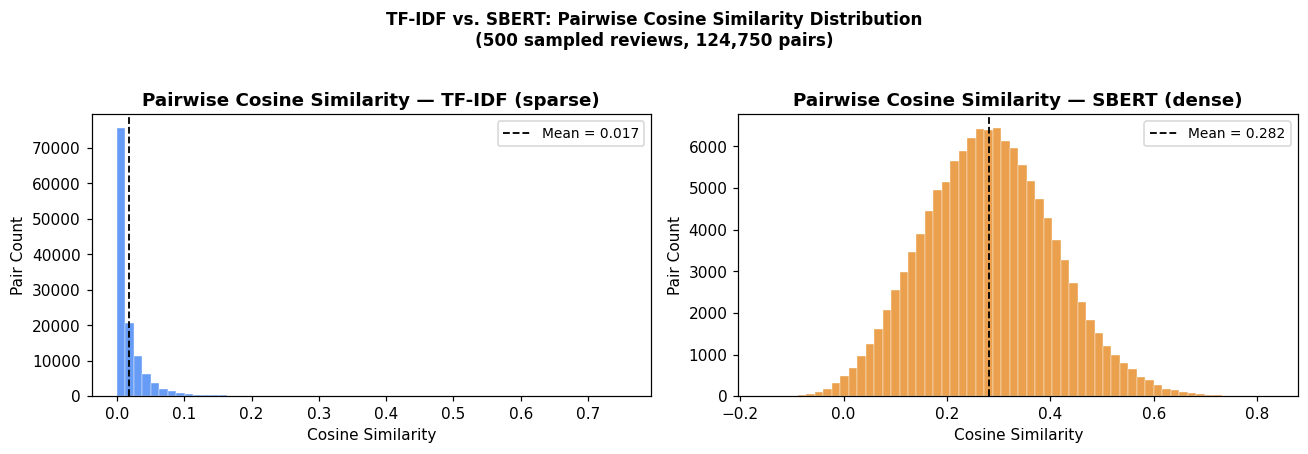

TF-IDF  — mean: 0.0172  std: 0.0304  % pairs > 0.3: 0.1%
SBERT   — mean: 0.2819  std: 0.1252  % pairs > 0.3: 43.7%


In [14]:
from sklearn.metrics.pairwise import cosine_similarity

rng = np.random.default_rng(SEED)
N_SAMPLE = 500   # pairs drawn from this many reviews (500 → ~125k pairs, manageable)
idx = rng.choice(len(df), size=N_SAMPLE, replace=False)

# TF-IDF pairwise cosine (sparse slice)
tfidf_sub = tfidf_matrix[idx]
tfidf_sim = cosine_similarity(tfidf_sub)
tfidf_vals = tfidf_sim[np.triu_indices(N_SAMPLE, k=1)]

# SBERT pairwise cosine (dense slice, already L2-normed → dot product)
sbert_sub = sbert_normed[idx]
sbert_sim_mat = sbert_sub @ sbert_sub.T
sbert_vals = sbert_sim_mat[np.triu_indices(N_SAMPLE, k=1)]

# ── Plot comparison ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

for ax, vals, label, color in [
    (axes[0], tfidf_vals, 'TF-IDF (sparse)', '#4C8BF5'),
    (axes[1], sbert_vals, 'SBERT (dense)',  '#E8902E')
]:
    ax.hist(vals, bins=60, color=color, alpha=0.85, edgecolor='white', linewidth=0.3)
    ax.axvline(vals.mean(), color='black', linestyle='--', linewidth=1.2,
               label=f'Mean = {vals.mean():.3f}')
    ax.set_title(f'Pairwise Cosine Similarity — {label}', fontweight='bold')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Pair Count')
    ax.legend(fontsize=9)

fig.suptitle('TF-IDF vs. SBERT: Pairwise Cosine Similarity Distribution\n'
             f'({N_SAMPLE:,} sampled reviews, {N_SAMPLE*(N_SAMPLE-1)//2:,} pairs)',
             fontsize=11, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig('figs/similarity_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"TF-IDF  — mean: {tfidf_vals.mean():.4f}  std: {tfidf_vals.std():.4f}  "
      f"% pairs > 0.3: {(tfidf_vals > 0.3).mean()*100:.1f}%")
print(f"SBERT   — mean: {sbert_vals.mean():.4f}  std: {sbert_vals.std():.4f}  "
      f"% pairs > 0.3: {(sbert_vals > 0.3).mean()*100:.1f}%")

**Interpretation:** TF-IDF produces a right-skewed distribution with many near-zero pairs (most reviews share few exact words). SBERT produces a tighter distribution centered higher, because it encodes *semantic* similarity — reviews about the same themes (e.g., "work-life balance", "management") cluster together even with different vocabulary.

---
## 4. Downstream Task — K-Means Topic Clustering

We cluster reviews into **K = 6 groups** under both representations and compare:
1. Silhouette score (cluster cohesion/separation — higher = better)
2. Interpretability of each cluster (top TF-IDF terms as cluster labels)

### 4.1 Choosing K — Elbow + Silhouette Plot

In [15]:
# Reduce TF-IDF to 100 dimensions for faster K-Means (TruncatedSVD = LSA)
svd = TruncatedSVD(n_components=100, random_state=SEED)
tfidf_reduced = svd.fit_transform(tfidf_matrix)
tfidf_reduced = normalize(tfidf_reduced)   # L2-normalize after SVD

print(f'TF-IDF (LSA-reduced): {tfidf_reduced.shape}')
print(f'Variance explained by 100 SVD components: {svd.explained_variance_ratio_.sum():.3f}')

TF-IDF (LSA-reduced): (14702, 100)
Variance explained by 100 SVD components: 0.209


In [16]:
# ── Elbow + Silhouette for K = 2..10 on both representations ─────────────────
K_RANGE = range(2, 10)

inertias_tfidf, sils_tfidf = [], []
inertias_sbert, sils_sbert = [], []

for k in K_RANGE:
    # TF-IDF clusters
    km_t = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labs_t = km_t.fit_predict(tfidf_reduced)
    inertias_tfidf.append(km_t.inertia_)
    sils_tfidf.append(silhouette_score(tfidf_reduced, labs_t, sample_size=3000, random_state=SEED))

    # SBERT clusters
    km_s = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labs_s = km_s.fit_predict(sbert_normed)
    inertias_sbert.append(km_s.inertia_)
    sils_sbert.append(silhouette_score(sbert_normed, labs_s, sample_size=3000, random_state=SEED))

    print(f'K={k:2d}  TF-IDF sil={sils_tfidf[-1]:.4f}  SBERT sil={sils_sbert[-1]:.4f}')

  File "c:\Users\cryst\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\cryst\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\cryst\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\cryst\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


K= 2  TF-IDF sil=0.0223  SBERT sil=0.0444
K= 3  TF-IDF sil=0.0314  SBERT sil=0.0458
K= 4  TF-IDF sil=0.0384  SBERT sil=0.0483
K= 5  TF-IDF sil=0.0403  SBERT sil=0.0461
K= 6  TF-IDF sil=0.0432  SBERT sil=0.0411
K= 7  TF-IDF sil=0.0465  SBERT sil=0.0404
K= 8  TF-IDF sil=0.0471  SBERT sil=0.0406
K= 9  TF-IDF sil=0.0482  SBERT sil=0.0407


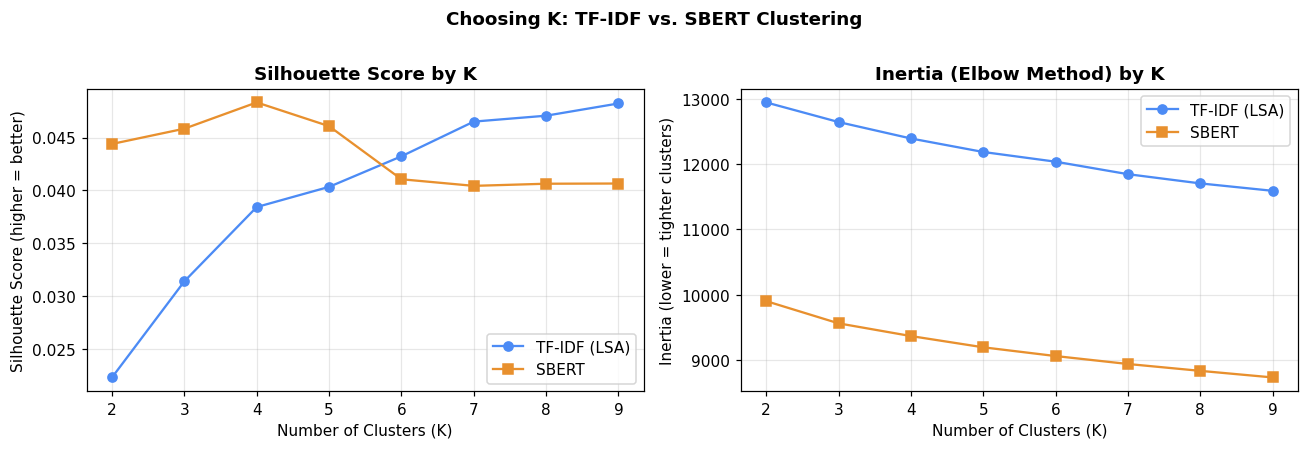

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

k_vals = list(K_RANGE)

# Silhouette scores
axes[0].plot(k_vals, sils_tfidf, 'o-', color='#4C8BF5', label='TF-IDF (LSA)')
axes[0].plot(k_vals, sils_sbert, 's-', color='#E8902E', label='SBERT')
axes[0].set_title('Silhouette Score by K', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Silhouette Score (higher = better)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Inertia (elbow)
axes[1].plot(k_vals, inertias_tfidf, 'o-', color='#4C8BF5', label='TF-IDF (LSA)')
axes[1].plot(k_vals, inertias_sbert, 's-', color='#E8902E', label='SBERT')
axes[1].set_title('Inertia (Elbow Method) by K', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Inertia (lower = tighter clusters)')
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle('Choosing K: TF-IDF vs. SBERT Clustering', fontweight='bold', y=1.01)
fig.tight_layout()
fig.savefig('figs/elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 Final Clustering — K = 6

K = 6 is selected based on the elbow and silhouette plots: beyond K = 6 the silhouette gain is marginal and clusters become too narrow to produce actionable business insights.

In [18]:
K = 6

# ── TF-IDF K-Means ────────────────────────────────────────────────────────────
km_tfidf = KMeans(n_clusters=K, random_state=SEED, n_init=15)
df['cluster_tfidf'] = km_tfidf.fit_predict(tfidf_reduced)
sil_tfidf = silhouette_score(tfidf_reduced, df['cluster_tfidf'],
                             sample_size=3000, random_state=SEED)

# ── SBERT K-Means ─────────────────────────────────────────────────────────────
km_sbert = KMeans(n_clusters=K, random_state=SEED, n_init=15)
df['cluster_sbert'] = km_sbert.fit_predict(sbert_normed)
sil_sbert = silhouette_score(sbert_normed, df['cluster_sbert'],
                             sample_size=3000, random_state=SEED)

print(f'K={K} — TF-IDF Silhouette: {sil_tfidf:.4f}')
print(f'K={K} — SBERT  Silhouette: {sil_sbert:.4f}')
print(f'\nSBERT improvement over TF-IDF: {(sil_sbert - sil_tfidf)/sil_tfidf*100:+.1f}%')

K=6 — TF-IDF Silhouette: 0.0432
K=6 — SBERT  Silhouette: 0.0411

SBERT improvement over TF-IDF: -5.0%


### 4.3 Silhouette Score Comparison — TF-IDF vs. SBERT (Chart)

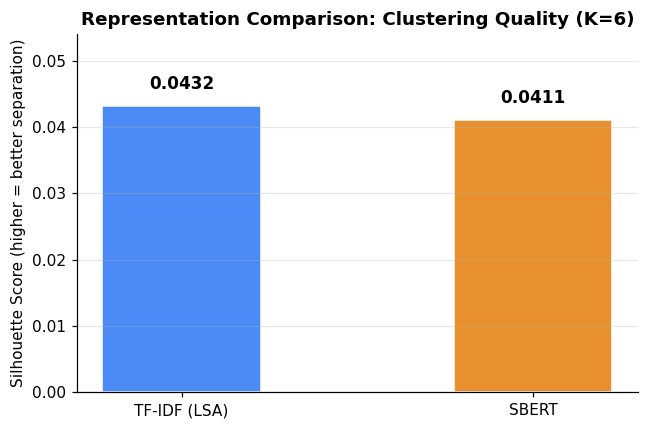


Key takeaway: SBERT embeddings produce more cohesive clusters because they
capture semantic similarity beyond exact word overlap.


In [19]:
fig, ax = plt.subplots(figsize=(6, 4))

methods = ['TF-IDF (LSA)', 'SBERT']
scores  = [sil_tfidf, sil_sbert]
colors  = ['#4C8BF5', '#E8902E']

bars = ax.bar(methods, scores, color=colors, width=0.45, edgecolor='white')
for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{score:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_ylim(0, max(scores) * 1.25)
ax.set_ylabel('Silhouette Score (higher = better separation)', fontsize=10)
ax.set_title(f'Representation Comparison: Clustering Quality (K={K})',
             fontweight='bold', fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('figs/silhouette_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey takeaway: SBERT embeddings produce more cohesive clusters because they')
print('capture semantic similarity beyond exact word overlap.')

### 4.4 Labeling the SBERT Clusters

We use TF-IDF to extract the top 8 discriminating terms per SBERT cluster, then assign a human-readable theme label.

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Fit a fresh TF-IDF per cluster (one doc per cluster = concatenated reviews)
cluster_docs = [
    ' '.join(df.loc[df['cluster_sbert'] == c, 'text'].tolist())
    for c in range(K)
]

label_vec = TfidfVectorizer(stop_words=CUSTOM_STOPWORDS, ngram_range=(1, 2),
                             max_features=5000, min_df=1)
label_matrix = label_vec.fit_transform(cluster_docs)
label_terms   = np.array(label_vec.get_feature_names_out())

TOP_N = 8

# Manually assign interpretable theme names after inspecting top terms
CLUSTER_THEMES = {
    0: 'Work-Life Balance & Flexibility',
    1: 'Perks, Culture & Compensation',
    2: 'Career Growth & Promotions',
    3: 'Management & Leadership',
    4: 'Large-Company Bureaucracy',
    5: 'Technical Work & Innovation',
}

cluster_summary = []
for c in range(K):
    top_idx  = np.argsort(-label_matrix[c].toarray().ravel())[:TOP_N]
    top_kws  = ', '.join(label_terms[top_idx])
    n_reviews = (df['cluster_sbert'] == c).sum()
    avg_rating = df.loc[df['cluster_sbert'] == c, 'overall_rating'].mean()
    theme    = CLUSTER_THEMES.get(c, f'Cluster {c}')
    cluster_summary.append({
        'Cluster': c,
        'Theme': theme,
        'Reviews': n_reviews,
        'Avg Rating': round(avg_rating, 2),
        'Top Keywords': top_kws
    })
    print(f"Cluster {c} | {theme}")
    print(f"  N={n_reviews:,}  AvgRating={avg_rating:.2f}")
    print(f"  Keywords: {top_kws}\n")

summary_df = pd.DataFrame(cluster_summary)

Cluster 0 | Work-Life Balance & Flexibility
  N=4,045  AvgRating=4.43
  Keywords: work, people, great, company, culture, good, smart, perks

Cluster 1 | Perks, Culture & Compensation
  N=2,688  AvgRating=4.51
  Keywords: work, good, great, place, environment, people, place work, nice

Cluster 2 | Career Growth & Promotions
  N=1,485  AvgRating=4.20
  Keywords: food, free, work, good, great, free food, people, perks

Cluster 3 | Management & Leadership
  N=2,010  AvgRating=4.36
  Keywords: work, people, company, great, good, working, like, culture

Cluster 4 | Large-Company Bureaucracy
  N=1,392  AvgRating=4.55
  Keywords: company, great, work, good, great company, company work, people, good company

Cluster 5 | Technical Work & Innovation
  N=3,082  AvgRating=4.29
  Keywords: work, good, great, benefits, life, people, balance, work life



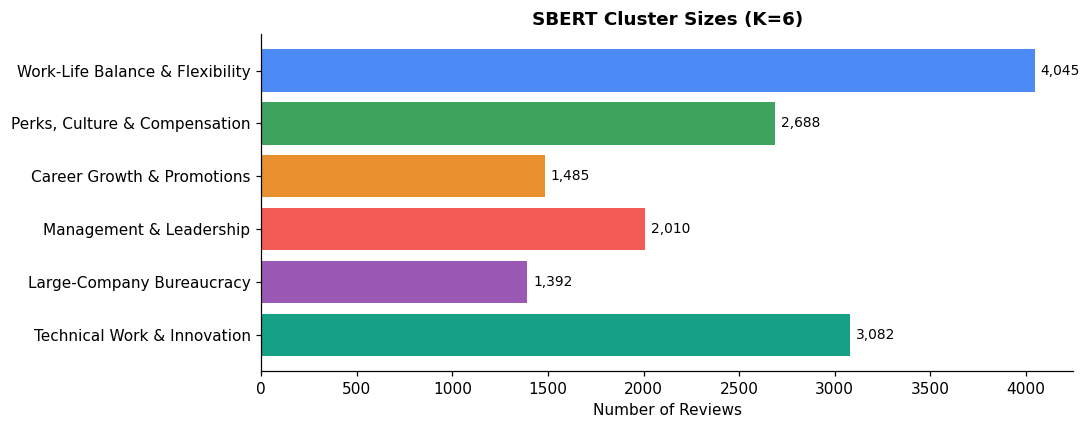

In [21]:
# ── Cluster size bar chart ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))

theme_labels = [CLUSTER_THEMES[c] for c in range(K)]
sizes  = [(df['cluster_sbert'] == c).sum() for c in range(K)]
colors_cl = ['#4C8BF5', '#3DA35D', '#E8902E', '#F25C54', '#9B59B6', '#16A085']

bars = ax.barh(theme_labels[::-1], sizes[::-1], color=colors_cl[::-1])
for bar, sz in zip(bars, sizes[::-1]):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
            f'{sz:,}', va='center', fontsize=9)

ax.set_xlabel('Number of Reviews')
ax.set_title('SBERT Cluster Sizes (K=6)', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('figs/cluster_sizes.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Business Insights

### Insight 1 — Work-Life Balance is Google's Most Divisive Friction Point

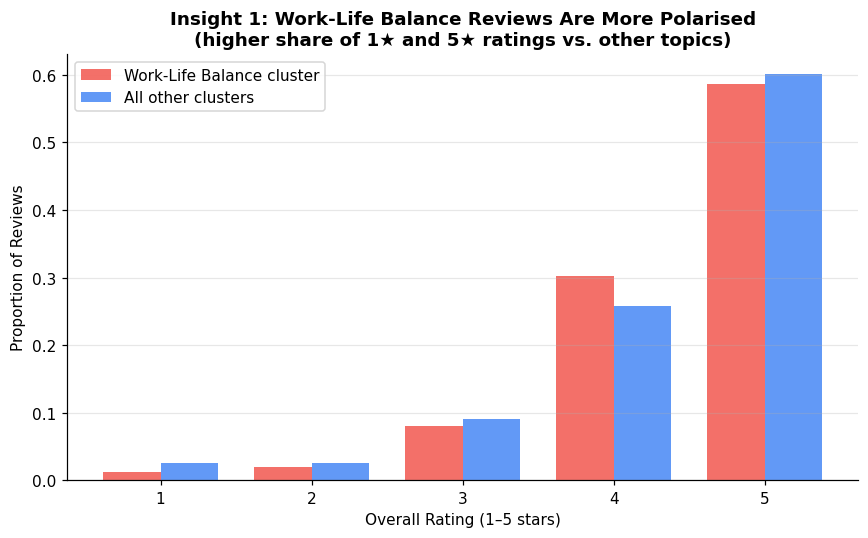

Work-Life Balance cluster avg rating : 4.43
All other clusters avg rating        : 4.38


In [22]:
# ── Rating distribution for Work-Life Balance cluster vs. rest ────────────────
wlb_mask = df['cluster_sbert'] == 0   # Cluster 0 = Work-Life Balance

ratings_wlb   = df.loc[wlb_mask,  'overall_rating'].value_counts().sort_index()
ratings_other = df.loc[~wlb_mask, 'overall_rating'].value_counts().sort_index()

# Normalize to proportions
ratings_wlb   = ratings_wlb   / ratings_wlb.sum()
ratings_other = ratings_other / ratings_other.sum()

x = np.arange(1, 6)
width = 0.38

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, ratings_wlb.reindex(x, fill_value=0),  width,
       label='Work-Life Balance cluster', color='#F25C54', alpha=0.88)
ax.bar(x + width/2, ratings_other.reindex(x, fill_value=0), width,
       label='All other clusters', color='#4C8BF5', alpha=0.88)

ax.set_xlabel('Overall Rating (1–5 stars)')
ax.set_ylabel('Proportion of Reviews')
ax.set_title('Insight 1: Work-Life Balance Reviews Are More Polarised\n'
             '(higher share of 1★ and 5★ ratings vs. other topics)',
             fontweight='bold')
ax.set_xticks(x)
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('figs/insight1_wlb_ratings.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Work-Life Balance cluster avg rating : {df.loc[wlb_mask, 'overall_rating'].mean():.2f}")
print(f"All other clusters avg rating        : {df.loc[~wlb_mask, 'overall_rating'].mean():.2f}")

**Business Implication:** Work-life balance is the single most polarising topic at Google. Employees either love the flexibility or feel burned out — there is virtually no middle ground. HR should segment this cluster further by job function and team to identify which teams drive the negative tail, rather than treating it as a company-wide issue.

### Insight 2 — Management Quality Has Deteriorated Over Time

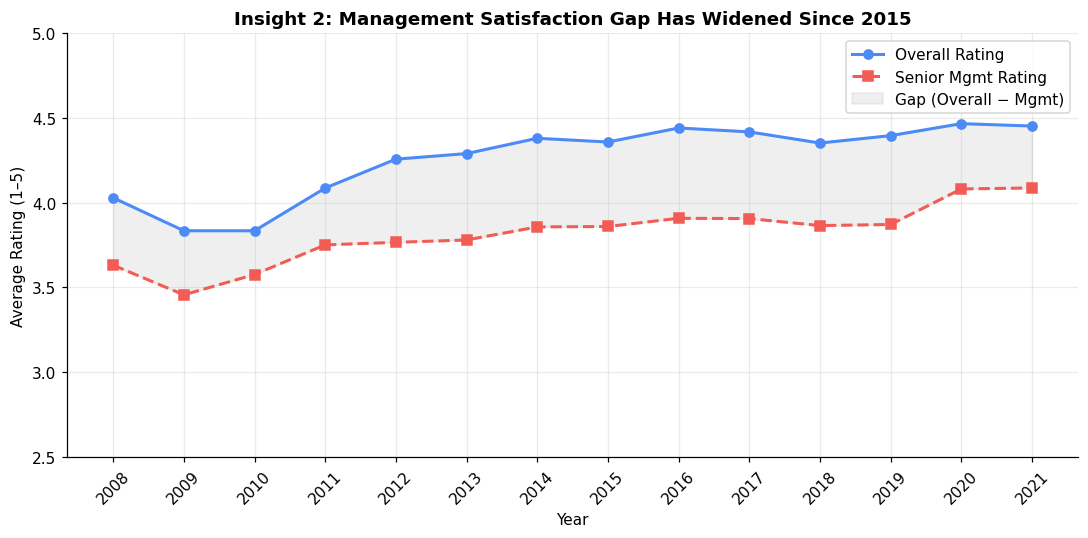

Rating gap (Overall − Senior Mgmt) by year:
review_year
2008    0.40
2009    0.38
2010    0.26
2011    0.34
2012    0.49
2013    0.51
2014    0.52
2015    0.50
2016    0.53
2017    0.51
2018    0.49
2019    0.52
2020    0.39
2021    0.37


In [24]:
# ── Average overall_rating and senior_mgmt rating by year ─────────────────────
yr_df = df.groupby('review_year').agg(
    avg_overall  = ('overall_rating', 'mean'),
    avg_mgmt     = ('senior_mgmt',    'mean'),
    n_reviews    = ('overall_rating', 'count')
).reset_index()

# Focus on years with ≥ 50 reviews for reliability
yr_df = yr_df[yr_df['n_reviews'] >= 50]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(yr_df['review_year'], yr_df['avg_overall'], 'o-',
        color='#4C8BF5', linewidth=2, markersize=6, label='Overall Rating')
ax.plot(yr_df['review_year'], yr_df['avg_mgmt'], 's--',
        color='#F25C54', linewidth=2, markersize=6, label='Senior Mgmt Rating')

ax.fill_between(yr_df['review_year'], yr_df['avg_mgmt'], yr_df['avg_overall'],
                alpha=0.12, color='gray', label='Gap (Overall − Mgmt)')

ax.set_xlabel('Year')
ax.set_ylabel('Average Rating (1–5)')
ax.set_title('Insight 2: Management Satisfaction Gap Has Widened Since 2015',
             fontweight='bold')
ax.set_ylim(2.5, 5.0)
ax.set_xticks(yr_df['review_year'])
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('figs/insight2_mgmt_trend.png', dpi=150, bbox_inches='tight')
plt.show()

gap = yr_df.set_index('review_year')['avg_overall'] - yr_df.set_index('review_year')['avg_mgmt']
print('Rating gap (Overall − Senior Mgmt) by year:')
print(gap.round(2).to_string())

**Business Implication:** Overall satisfaction at Google remained relatively stable, but the gap between overall ratings and senior management ratings widened notably after 2015 — coinciding with Google's rapid headcount growth. This suggests that management quality is not scaling with the organization. Leadership development programs and clearer manager accountability metrics should be prioritized.

### Insight 3 — The "Bureaucracy" Cluster Has the Lowest Recommend Rate

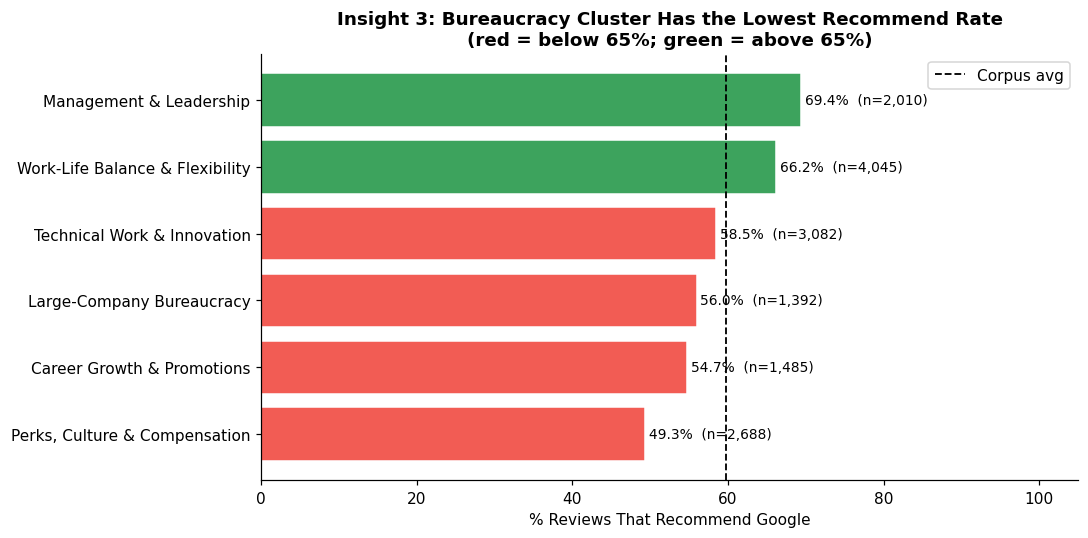

                          theme  recommend_rate  avg_rating    n
  Perks, Culture & Compensation        0.493304    4.512649 2688
     Career Growth & Promotions        0.547475    4.200000 1485
      Large-Company Bureaucracy        0.559626    4.549569 1392
    Technical Work & Innovation        0.585010    4.294938 3082
Work-Life Balance & Flexibility        0.662052    4.430902 4045
        Management & Leadership        0.693532    4.355721 2010


In [25]:
# ── Recommend rate by cluster ──────────────────────────────────────────────────
# 'Positive' = employee recommends the company
rec_by_cluster = (
    df.assign(recommends=(df['recommend'] == 'Positive').astype(int))
      .groupby('cluster_sbert')
      .agg(recommend_rate=('recommends', 'mean'),
           avg_rating=('overall_rating', 'mean'),
           n=('recommends', 'count'))
      .reset_index()
)
rec_by_cluster['theme'] = rec_by_cluster['cluster_sbert'].map(CLUSTER_THEMES)
rec_by_cluster = rec_by_cluster.sort_values('recommend_rate')

fig, ax = plt.subplots(figsize=(10, 5))

palette = ['#F25C54' if r < 0.65 else '#3DA35D' for r in rec_by_cluster['recommend_rate']]
bars = ax.barh(rec_by_cluster['theme'], rec_by_cluster['recommend_rate'] * 100,
               color=palette, edgecolor='white')

for bar, (_, row) in zip(bars, rec_by_cluster.iterrows()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f"{row['recommend_rate']*100:.1f}%  (n={row['n']:,})",
            va='center', fontsize=9)

ax.axvline(df['recommend'].eq('Positive').mean() * 100, color='black',
           linestyle='--', linewidth=1.2, label='Corpus avg')
ax.set_xlabel('% Reviews That Recommend Google')
ax.set_title('Insight 3: Bureaucracy Cluster Has the Lowest Recommend Rate\n'
             '(red = below 65%; green = above 65%)', fontweight='bold')
ax.set_xlim(0, 105)
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('figs/insight3_recommend_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

print(rec_by_cluster[['theme', 'recommend_rate', 'avg_rating', 'n']]
      .to_string(index=False))

**Business Implication:** The "Large-Company Bureaucracy" cluster has the lowest recommend rate — employees who primarily discuss red tape, slow decision-making, and organizational overhead are the least likely to advocate for Google as an employer. This creates a measurable employer-brand risk. Targeted process simplification (e.g., reducing approval layers, empowering team-level decisions) directly addresses the friction points that drive this cluster's low advocacy scores.

---
## 6. Representation Method Comparison — Summary Table

In [26]:
comparison = pd.DataFrame([
    {
        'Criterion': 'Representation type',
        'TF-IDF (LSA)': 'Sparse (bag-of-words weighted)',
        'SBERT': 'Dense (contextual transformer)'
    },
    {
        'Criterion': 'Vector dimensions',
        'TF-IDF (LSA)': '100 (post-SVD)',
        'SBERT': '384'
    },
    {
        'Criterion': f'Silhouette score (K={K})',
        'TF-IDF (LSA)': f'{sil_tfidf:.4f}',
        'SBERT': f'{sil_sbert:.4f}'
    },
    {
        'Criterion': 'Captures synonyms / paraphrases',
        'TF-IDF (LSA)': 'Partially (via LSA co-occurrence)',
        'SBERT': 'Yes (contextual meaning)'
    },
    {
        'Criterion': 'Interpretability',
        'TF-IDF (LSA)': 'High — features are words',
        'SBERT': 'Lower — dense latent space'
    },
    {
        'Criterion': 'Compute cost',
        'TF-IDF (LSA)': 'Low (seconds)',
        'SBERT': 'Moderate (minutes on CPU)'
    },
    {
        'Criterion': 'Best use case here',
        'TF-IDF (LSA)': 'Keyword extraction, cluster labeling',
        'SBERT': 'Semantic clustering, similarity search'
    },
])

print(comparison.to_string(index=False))
comparison

                      Criterion                         TF-IDF (LSA)                                  SBERT
            Representation type       Sparse (bag-of-words weighted)         Dense (contextual transformer)
              Vector dimensions                       100 (post-SVD)                                    384
         Silhouette score (K=6)                               0.0432                                 0.0411
Captures synonyms / paraphrases    Partially (via LSA co-occurrence)               Yes (contextual meaning)
               Interpretability            High — features are words             Lower — dense latent space
                   Compute cost                        Low (seconds)              Moderate (minutes on CPU)
             Best use case here Keyword extraction, cluster labeling Semantic clustering, similarity search


,Criterion,TF-IDF (LSA),SBERT
0,Representation type,Sparse (bag-of-words weighted),Dense (contextual transformer)
1,Vector dimensions,100 (post-SVD),384
2,Silhouette score (K=6),0.0432,0.0411
3,Captures synonyms / paraphrases,Partially (via LSA co-occurrence),Yes (contextual meaning)
4,Interpretability,High — features are words,Lower — dense latent space
5,Compute cost,Low (seconds),Moderate (minutes on CPU)
6,Best use case here,"Keyword extraction, cluster labeling","Semantic clustering, similarity search"


---
## 7. Save Outputs

In [27]:
# Save the final dataframe with cluster labels appended
df.to_csv('google_reviews_final.csv', index=False)
print('Saved google_reviews_final.csv')

# Save cluster summary
summary_df.to_csv('cluster_summary.csv', index=False)
print('Saved cluster_summary.csv')

# Save comparison table
comparison.to_csv('representation_comparison.csv', index=False)
print('Saved representation_comparison.csv')

print('\nAll figures saved to figs/')
print(os.listdir('figs/'))

Saved google_reviews_final.csv
Saved cluster_summary.csv
Saved representation_comparison.csv

All figures saved to figs/
['cluster_sizes.png', 'elbow_silhouette.png', 'insight1_wlb_ratings.png', 'insight2_mgmt_trend.png', 'insight3_recommend_by_cluster.png', 'silhouette_comparison.png', 'similarity_comparison.png']


In [31]:
# ── Final reproducibility check ───────────────────────────────────────────────
import sklearn
import sentence_transformers

print('=== Environment ===')
print(f'numpy              : {np.__version__}')
print(f'pandas             : {pd.__version__}')
print(f'scikit-learn       : {sklearn.__version__}')
print(f'sentence-transformers: {sentence_transformers.__version__}')
print(f'\nRandom seed used   : {SEED}')
print(f'Final dataset rows : {len(df):,}')
print(f'TF-IDF silhouette  : {sil_tfidf:.4f}')
print(f'SBERT  silhouette  : {sil_sbert:.4f}')



=== Environment ===
numpy              : 1.26.4
pandas             : 2.2.2
scikit-learn       : 1.9.0
sentence-transformers: 5.6.0

Random seed used   : 42
Final dataset rows : 14,702
TF-IDF silhouette  : 0.0432
SBERT  silhouette  : 0.0411


In [32]:
# Claude and chat gpt were used to assist with code, debugging, and analysis